# Downloading MICrONS

The code below will download parts of the MICrONS database that we are interested in. Specifically, we're looking for:
- Neurons with calcium imaging data
- Neuron pairs that have proofread synapses

To do this, you need to get an API token for CAVE. Here's how you go about doing that:
1. Go to https://global.daf-apis.com/auth/api/v1/create_token to create a new token
2. Log in with your Google credentials and copy the token shown afterward
3. Paste your token into the `.env` file (you create yourself) under `TOKEN=`

In [89]:
%pip install -U caveclient pandas numpy python-dotenv

  Using cached pandas-3.0.6-cp313-cp313-macosx_11_0_arm64.whl.metadata (79 kB)

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [90]:
import os
from dotenv import load_dotenv
from caveclient import CAVEclient

load_dotenv()

client = CAVEclient(
  datastack_name="minnie65_public",
  version=1926,
  auth_token=os.getenv("TOKEN"),
)

## 1. Check which neurons are proofread
Some neurons are proofread, and to different levels. Here is the procedure:
1. Filter for valid records (`valid=True`)
2. Filter for either `status_dendrite | status_axon=True` and `strategy_axon=axon_fully_extended | strategy_dendrite=dendrite_extended`
3. Confirm exactly one record per neuron (`pt_root_id`) and construct list

In [91]:
proofread_df = client.materialize.query_table(
  "proofreading_status_and_strategy",
  desired_resolution=[1, 1, 1],
  split_positions=True,
)
print(proofread_df.columns.to_list())
display(proofread_df.head())

['id', 'created', 'superceded_id', 'valid', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'valid_id', 'status_dendrite', 'status_axon', 'strategy_dendrite', 'strategy_axon', 'pt_supervoxel_id', 'pt_root_id']


,id,created,superceded_id,valid,pt_position_x,pt_position_y,pt_position_z,valid_id,status_dendrite,status_axon,strategy_dendrite,strategy_axon,pt_supervoxel_id,pt_root_id
0,4584,2025-11-17 21:56:20.328504+00:00,<NA>,True,1185856,444800,670800,864691135686494647,True,True,dendrite_extended,axon_fully_extended,105489482232831453,864691135686494647
1,5952,2026-09-23 00:07:17.663435+00:00,<NA>,True,716644,859320,1086120,864691135210716537,False,True,none,axon_fully_extended,89388991278804869,864691135210716537
2,5953,2026-09-23 00:53:52.311874+00:00,<NA>,True,821632,418368,883000,864691135939998724,True,True,dendrite_extended,axon_fully_extended,93033321898015624,864691135939998724
3,9,2024-06-03 19:45:52.508002+00:00,<NA>,True,1329476,475260,700720,864691136812081779,True,True,dendrite_extended,axon_interareal,110486693995521385,864691136812081779
4,14,2024-06-03 19:45:52.512832+00:00,<NA>,True,692736,869888,877160,864691136195284556,True,True,dendrite_extended,axon_fully_extended,88615277952475942,864691136195284556


In [ ]:
n_records = proofread_df.shape[0]
proofread_valid_df = proofread_df[
  (proofread_df["valid"] == True) &
  (
    (proofread_df["status_axon"] == True) |
    (proofread_df["status_dendrite"] == True)
  ) &
  (
    (proofread_df["strategy_axon"] == "axon_fully_extended") |
    (proofread_df["strategy_dendrite"] == "dendrite_extended")
  ) &
  (proofread_df["valid_id"] == proofread_df["pt_root_id"])
].copy()
n_valid_records = proofread_valid_df.shape[0]

proofread_pre_ids = set(proofread_valid_df[proofread_df["strategy_axon"] == "axon_fully_extended"].copy()["pt_root_id"].astype("int64"))
proofread_post_ids = set(proofread_valid_df[proofread_df["strategy_dendrite"] == "dendrite_extended"].copy()["pt_root_id"].astype("int64"))
proofread_ids = proofread_pre_ids.union(proofread_post_ids)

print(f"n_records=        {n_records}")
print(f"n_valid_records=  {n_valid_records}")
print(f"n_pr_pre=         {len(proofread_pre_ids)}")
print(f"n_pr_post=        {len(proofread_post_ids)}")

n_records=        2345
n_valid_records=  2343
n_pr_pre=         802
n_pr_post=        2021


/var/folders/kt/6dtp82192078vqz9pmrb32lm0000gn/T/ipykernel_59964/3201739764.py:16: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  proofread_pre_ids = set(proofread_valid_df[proofread_df["strategy_axon"] == "axon_fully_extended"].copy()["pt_root_id"].astype("int64"))
/var/folders/kt/6dtp82192078vqz9pmrb32lm0000gn/T/ipykernel_59964/3201739764.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  proofread_post_ids = set(proofread_valid_df[proofread_df["strategy_dendrite"] == "dendrite_extended"].copy()["pt_root_id"].astype("int64"))


## 2. Find all calcium-imaged and EM-imaged neurons

Basic query and filtering. Not hard.

In [123]:
coreg_df = client.materialize.query_table(
  "coregistration_manual_v4",
  desired_resolution=[1, 1, 1],
  split_positions=True,
)
print(coreg_df.columns.to_list())
display(coreg_df.head())

['id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id', 'pt_root_id', 'id', 'created', 'valid', 'target_id', 'session', 'scan_idx', 'unit_id', 'field', 'residual', 'score']


,id_ref,created_ref,valid_ref,volume,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,...,id,created,valid,target_id,session,scan_idx,unit_id,field,residual,score
0,492564,2020-09-28 22:41:00.815893+00:00,True,312.260376,1126848,697600,711480,<NA>,<NA>,<NA>,...,4229,2024-05-21 18:38:24.663935+00:00,True,492564,5,7,7276,6,4.9403,6.3722
1,335649,2020-09-28 22:41:20.303372+00:00,True,295.861115,843136,728128,906920,<NA>,<NA>,<NA>,...,5491,2024-05-21 18:38:25.372047+00:00,True,335649,6,2,6883,6,7.41244,2.60806
2,224395,2020-09-28 22:41:32.572651+00:00,True,329.448334,599360,532608,903680,<NA>,<NA>,<NA>,...,10490,2024-05-21 18:42:39.170710+00:00,True,224395,7,3,2398,2,7.02217,-1.39408
3,224395,2020-09-28 22:41:32.572651+00:00,True,329.448334,599360,532608,903680,<NA>,<NA>,<NA>,...,19021,2024-05-21 18:42:43.833831+00:00,True,224395,9,6,4843,4,9.55213,5.02637
4,332833,2020-09-28 22:44:41.864456+00:00,True,274.418732,837312,697216,800160,<NA>,<NA>,<NA>,...,9672,2024-05-21 18:42:38.724265+00:00,True,332833,6,7,6413,6,5.27806,7.80804


In [124]:
coreg_df = coreg_df[coreg_df["valid"] == True].copy()
coreg_df = coreg_df.drop_duplicates(subset=["pt_root_id", "session", "scan_idx", "unit_id"])

coreg_ids = set(coreg_df["pt_root_id"].astype("int64"))

print(f"n_coreg_ids=  {len(coreg_ids)}")

n_coreg_ids=  15434


In [152]:
FILTER_PROOFREAD = 0
FILTER_NONE = 1
FILTER_FIRST = 2

filter_type = FILTER_FIRST

if filter_type == FILTER_PROOFREAD:
  valid_coreg_df = coreg_df[coreg_df["pt_root_id"].isin(proofread_ids)].copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_pre_ids = valid_coreg_ids.intersection(proofread_pre_ids)
  valid_coreg_post_ids = valid_coreg_ids.intersection(proofread_post_ids)
elif filter_type == FILTER_NONE:
  valid_coreg_df = coreg_df.copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_pre_ids = valid_coreg_ids
  valid_coreg_post_ids = valid_coreg_ids
elif filter_type == FILTER_FIRST:
  valid_coreg_df = coreg_df.copy()
  valid_coreg_ids = set(valid_coreg_df["pt_root_id"].astype("int64"))
  valid_coreg_ids = set(list(valid_coreg_ids)[:3000])
  valid_coreg_df = valid_coreg_df[valid_coreg_df["pt_root_id"].isin(valid_coreg_ids)]
  valid_coreg_pre_ids = valid_coreg_ids
  valid_coreg_post_ids = valid_coreg_ids
else:
  exit(1)

print(f"n_valid_coreg_ids=     {len(valid_coreg_ids)}")
print(f"valid_coreg_pre_ids=   {len(valid_coreg_post_ids)}")
print(f"valid_coreg_post_ids=  {len(valid_coreg_post_ids)}")

n_valid_coreg_ids=     3000
valid_coreg_pre_ids=   3000
valid_coreg_post_ids=  3000


## 3. Load all synapses that we care about

Again, basic querying. No filtering this time.

In [153]:
from pathlib import Path
import pandas as pd

pre_ids = sorted(map(int, valid_coreg_pre_ids))
post_ids = sorted(map(int, valid_coreg_post_ids))

cache_dir = Path("cache/synapse_batches")
cache_dir.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 500
batch_files = []

pre_batches = [
  pre_ids[i:i + BATCH_SIZE]
  for i in range(0, len(pre_ids), BATCH_SIZE)
]
post_batches = [
  post_ids[i:i + BATCH_SIZE]
  for i in range(0, len(post_ids), BATCH_SIZE)
]

for i, pre_batch in enumerate(pre_batches):
  for j, post_batch in enumerate(post_batches):
    batch_path = cache_dir / f"pre_{i}_post_{j}.parquet"
    batch_files.append(batch_path)

    if batch_path.exists():
      print(f"Cached batch {i}, {j}")
      continue

    print(f"Querying batch {i + 1}/{len(pre_batches)}, {j + 1}/{len(post_batches)}")

    df = client.materialize.query_table(
      "synapses_pni_2",
      filter_in_dict={
          "pre_pt_root_id": pre_batch,
          "post_pt_root_id": post_batch,
      },
      select_columns=[
          "pre_pt_root_id",
          "post_pt_root_id",
      ],
      materialization_version=1926,
    )
    df.to_parquet(batch_path, index=False)

synapses_df = pd.concat(
  [pd.read_parquet(path) for path in batch_files],
  ignore_index=True,
).drop_duplicates()

print(synapses_df.columns.to_list())
print(synapses_df.head())

Querying batch 1/6, 1/6
Querying batch 1/6, 2/6
Querying batch 1/6, 3/6
Querying batch 1/6, 4/6
Querying batch 1/6, 5/6
Querying batch 1/6, 6/6
Querying batch 2/6, 1/6
Querying batch 2/6, 2/6
Querying batch 2/6, 3/6
Querying batch 2/6, 4/6
Querying batch 2/6, 5/6
Querying batch 2/6, 6/6
Querying batch 3/6, 1/6
Querying batch 3/6, 2/6
Querying batch 3/6, 3/6
Querying batch 3/6, 4/6
Querying batch 3/6, 5/6
Querying batch 3/6, 6/6
Querying batch 4/6, 1/6
Querying batch 4/6, 2/6
Querying batch 4/6, 3/6
Querying batch 4/6, 4/6
Querying batch 4/6, 5/6
Querying batch 4/6, 6/6
Querying batch 5/6, 1/6
Querying batch 5/6, 2/6
Querying batch 5/6, 3/6
Querying batch 5/6, 4/6
Querying batch 5/6, 5/6
Querying batch 5/6, 6/6
Querying batch 6/6, 1/6
Querying batch 6/6, 2/6
Querying batch 6/6, 3/6
Querying batch 6/6, 4/6
Querying batch 6/6, 5/6
Querying batch 6/6, 6/6
['pre_pt_supervoxel_id', 'pre_pt_root_id', 'post_pt_supervoxel_id', 'post_pt_root_id']
   pre_pt_supervoxel_id      pre_pt_root_id  post

In [160]:
synapses_df = synapses_df[
  synapses_df["pre_pt_root_id"].isin(valid_coreg_pre_ids) &
  synapses_df["post_pt_root_id"].isin(valid_coreg_post_ids)
]
synapses_df = synapses_df[synapses_df["pre_pt_root_id"] != synapses_df["post_pt_root_id"]]

# just makin' sure i didn't screw up
assert len(valid_coreg_pre_ids.union(set(synapses_df["pre_pt_root_id"].astype("int64")))) == len(valid_coreg_pre_ids)
assert len(valid_coreg_post_ids.union(set(synapses_df["post_pt_root_id"].astype("int64")))) == len(valid_coreg_post_ids)

n_synapses = synapses_df.shape[0]

print(f"n_synapses=  {n_synapses}")

n_synapses=  20320


# Building Benchmarks

We're going to set up some benchmarks to evaluate our model against.

## KNN Euclidian Distance Benchmark

This works by using a simple distance threshold to determine whether two neurons are connected or not. But first, to determine how to choose that threshold, we will plot all synaptic distances and nonsynaptic distances.

In [161]:
%pip install -U matplotlib scipy scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [162]:
import numpy as np
from scipy.spatial.distance import cdist

coords_df = coreg_df.drop_duplicates("pt_root_id").set_index("pt_root_id")

pre_ids = np.asarray(list(valid_coreg_pre_ids), dtype=np.int64)
post_ids = np.asarray(list(valid_coreg_post_ids), dtype=np.int64)

pre_xyz = coords_df.loc[
  pre_ids, ["pt_position_x", "pt_position_y", "pt_position_z"]
].to_numpy(dtype=float)

post_xyz = coords_df.loc[
  post_ids, ["pt_position_x", "pt_position_y", "pt_position_z"]
].to_numpy(dtype=float)

pair_counts = (
  synapses_df
  .groupby(["pre_pt_root_id", "post_pt_root_id"])
  .size()
  .rename("n")
  .reset_index()
)

distance_matrix = cdist(pre_xyz, post_xyz)

pre_idx = {root_id: i for i, root_id in enumerate(pre_ids)}
post_idx = {root_id: i for i, root_id in enumerate(post_ids)}

pair_counts["distance"] = [
  distance_matrix[pre_idx[pre], post_idx[post]]
  for pre, post in zip(
    pair_counts["pre_pt_root_id"],
    pair_counts["post_pt_root_id"],
  )
]

synaptic_distances = np.repeat(
  pair_counts["distance"].to_numpy(),
  pair_counts["n"].to_numpy(),
)

connected_pairs = set(zip(
  pair_counts["pre_pt_root_id"],
  pair_counts["post_pt_root_id"],
))

nonsynaptic_distances = []

for i, pre in enumerate(pre_ids):
  for j, post in enumerate(post_ids):
    if (pre, post) not in connected_pairs:
      nonsynaptic_distances.append(distance_matrix[i, j])

nonsynaptic_distances = np.asarray(nonsynaptic_distances)

assert len(synaptic_distances) == n_synapses

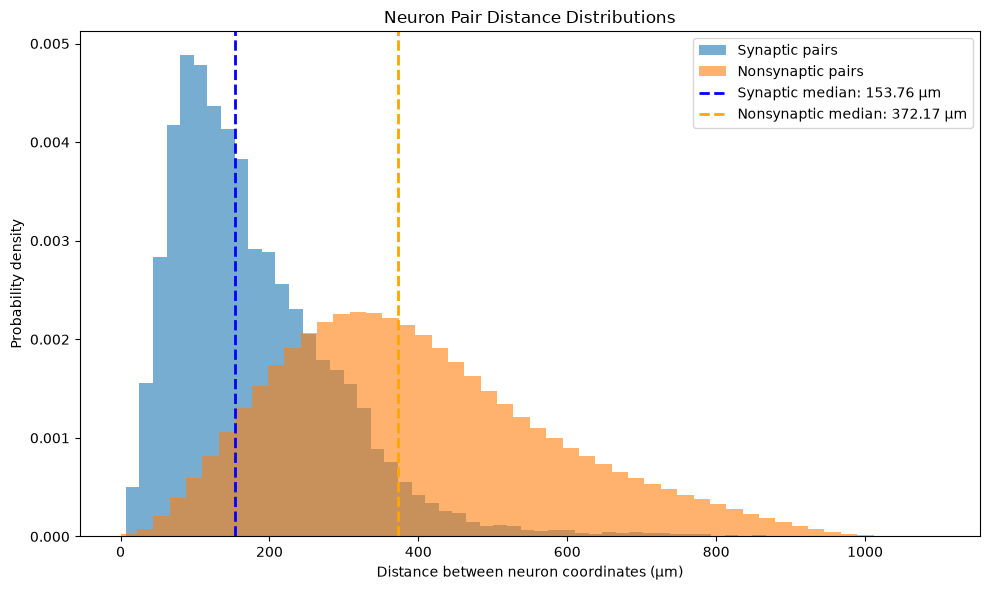

syn_median=     153.76 μm
nonsyn_median=  372.17 μm


In [163]:
import numpy as np
import matplotlib.pyplot as plt

synaptic_distances_um = synaptic_distances / 1000
nonsynaptic_distances_um = nonsynaptic_distances / 1000

synaptic_median = np.median(synaptic_distances_um)
nonsynaptic_median = np.median(nonsynaptic_distances_um)

plt.figure(figsize=(10, 6))

plt.hist(
  synaptic_distances_um,
  bins=50,
  alpha=0.6,
  density=True,
  label="Synaptic pairs",
)

plt.hist(
  nonsynaptic_distances_um,
  bins=50,
  alpha=0.6,
  density=True,
  label="Nonsynaptic pairs",
)

plt.axvline(
  synaptic_median,
  color="blue",
  linestyle="--",
  linewidth=2,
  label=f"Synaptic median: {synaptic_median:.2f} μm",
)

plt.axvline(
  nonsynaptic_median,
  color="orange",
  linestyle="--",
  linewidth=2,
  label=f"Nonsynaptic median: {nonsynaptic_median:.2f} μm",
)

plt.xlabel("Distance between neuron coordinates (μm)")
plt.ylabel("Probability density")
plt.title("Neuron Pair Distance Distributions")
plt.legend()
plt.tight_layout()
plt.show()

print(f"syn_median=     {synaptic_median:.2f} μm")
print(f"nonsyn_median=  {nonsynaptic_median:.2f} μm")


Find the best distance that maximizes both left area for synaptic and right area for nonsynaptic, normalized.

In [166]:
# Candidate thresholds: midpoints between observed distances
values = np.sort(np.unique(np.concatenate([synaptic_distances, nonsynaptic_distances])))
thresholds = (values[:-1] + values[1:]) / 2

syn_left = np.searchsorted(np.sort(synaptic_distances), thresholds, side="right") / len(synaptic_distances)
nonsyn_right = (len(nonsynaptic_distances) - np.searchsorted(np.sort(nonsynaptic_distances), thresholds, side="right")) / len(nonsynaptic_distances)

score = (syn_left + nonsyn_right) / 2

best_idx = np.argmax(score)
best_distance = thresholds[best_idx]

print(f"d_thresh=  {best_distance:.2f}")
print(f"syn_A=     {syn_left[best_idx]:.3%}")
print(f"nonsyn_A=  {nonsyn_right[best_idx]:.3%}")
print(f"accuracy=  {score[best_idx]:.3%}")

d_thresh=  245598.61
syn_A=     76.580%
nonsyn_A=  78.046%
accuracy=  77.313%


Evaulate this against every neuron pair to see true accuracy.

In [167]:
import numpy as np
from scipy.spatial.distance import cdist
from sklearn.metrics import (
  accuracy_score, precision_score, recall_score, f1_score,
  confusion_matrix, classification_report, roc_auc_score,
  average_precision_score,
)

coords = coreg_df.drop_duplicates("pt_root_id").set_index("pt_root_id")

pre_ids = np.array(list(valid_coreg_pre_ids), dtype=np.int64)
post_ids = np.array(list(valid_coreg_post_ids), dtype=np.int64)

distance_matrix = cdist(pre_xyz, post_xyz)

pre_idx = {nid: i for i, nid in enumerate(pre_ids)}
post_idx = {nid: i for i, nid in enumerate(post_ids)}

y_true_matrix = np.zeros(distance_matrix.shape, dtype=np.uint8)

pairs = synapses_df[["pre_pt_root_id", "post_pt_root_id"]].drop_duplicates()

for pre, post in pairs.itertuples(index=False, name=None):
  if pre in pre_idx and post in post_idx:
    y_true_matrix[pre_idx[pre], post_idx[post]] = 1

y_true = y_true_matrix.flatten()
pair_distances = distance_matrix.flatten()

y_pred = (pair_distances <= best_distance).astype(np.uint8)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

print(f"TP={tp}  FP={fp}  TN={tn}  FN={fn}")
print(f"accuracy=       {accuracy_score(y_true, y_pred):.4f}")
print(f"precision=      {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"recall=         {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"specificity=    {tn / (tn + fp) if tn + fp else 0:.4f}")
print(f"f1=             {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC=        {roc_auc_score(y_true, -pair_distances):.4f}")
print(f"avg_precision=  {average_precision_score(y_true, -pair_distances):.4f}")

print(classification_report(
  y_true, y_pred,
  target_names=["Nonsynaptic", "Synaptic"],
  zero_division=0,
))

TP=13783  FP=1971959  TN=7010216  FN=4042
accuracy=       0.7804
precision=      0.0069
recall=         0.7732
specificity=    0.7805
f1=             0.0138
ROC-AUC=        0.8591
avg_precision=  0.0158
              precision    recall  f1-score   support

 Nonsynaptic       1.00      0.78      0.88   8982175
    Synaptic       0.01      0.77      0.01     17825

    accuracy                           0.78   9000000
   macro avg       0.50      0.78      0.45   9000000
weighted avg       1.00      0.78      0.87   9000000

